<a href="https://colab.research.google.com/github/lnambiar18/Nambiar_Lohit_HW5_DSCI552/blob/main/Nambiar_Lohit_HW5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<center><h1>Nambiar_Lohit_HW5</h1></center>
<br>
<br>

Name: Lohit Nambiar
<br>
Github Username: lnambiar18
<br>
USC ID: 8395177707

## 1. Decision Trees as Interpretable Models

Import packages

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.tree import export_text
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.decomposition import PCA
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [19]:
columns = ["temperature", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains", "burning_urethra", "bladder_inflammation", "nephritis"]
data = pd.read_csv("diagnosis.data", sep = r"\s+", header = None, names = columns,decimal = ",", encoding = "utf-16")

print(data.shape)
data.head()

(120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### (b) Build a decision tree

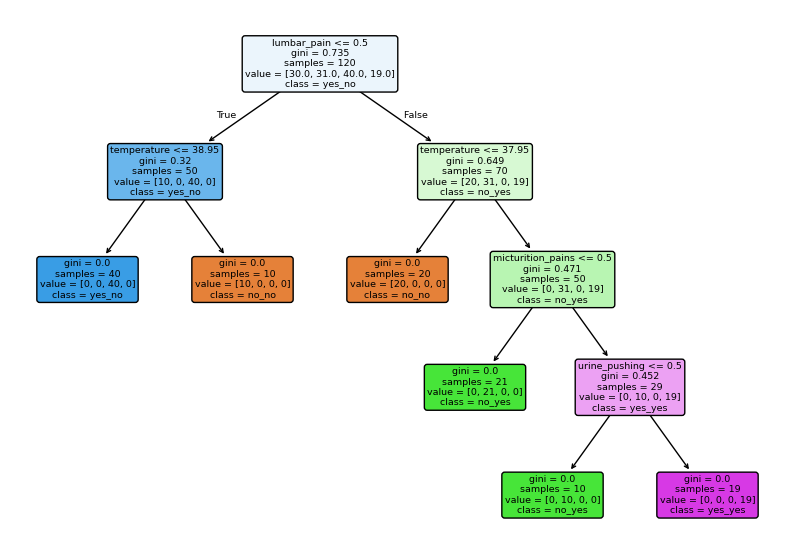

In [20]:
X = data.iloc[:, :6].copy()

for column in X.columns[1:]:
    X[column] = X[column].map({"no": 0, "yes": 1})

y = data[["bladder_inflammation", "nephritis"]].astype(str).agg("_".join, axis = 1)

tree = DecisionTreeClassifier(random_state = 1018)
tree.fit(X, y)

plt.figure(figsize=(10, 7))
plot_tree(tree, feature_names = X.columns, class_names = tree.classes_, filled = True, rounded = True)
plt.show()

### (c) Convert the decision rules

In [21]:
rules = export_text(tree, feature_names = list(X.columns), decimals = 2)
print(rules)

|--- lumbar_pain <= 0.50
|   |--- temperature <= 38.95
|   |   |--- class: yes_no
|   |--- temperature >  38.95
|   |   |--- class: no_no
|--- lumbar_pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: no_no
|   |--- temperature >  37.95
|   |   |--- micturition_pains <= 0.50
|   |   |   |--- class: no_yes
|   |   |--- micturition_pains >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: no_yes
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: yes_yes



### (d) Find minimal decision tree and a set of decision rules with high interpretability

Chosen alpha: 0.0
Leaves before pruning: 6
Leaves after pruning: 6
Cross-validation accuracy: 0.9583333333333334


,alpha,leaves,cv_accuracy
0,0.000000,6,0.958333
1,0.098167,4,0.775000
2,0.133333,3,0.716667
3,0.182000,2,0.600000
4,0.222917,1,0.433333


|--- lumbar_pain <= 0.50
|   |--- temperature <= 38.95
|   |   |--- class: yes_no
|   |--- temperature >  38.95
|   |   |--- class: no_no
|--- lumbar_pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: no_no
|   |--- temperature >  37.95
|   |   |--- micturition_pains <= 0.50
|   |   |   |--- class: no_yes
|   |   |--- micturition_pains >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: no_yes
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: yes_yes



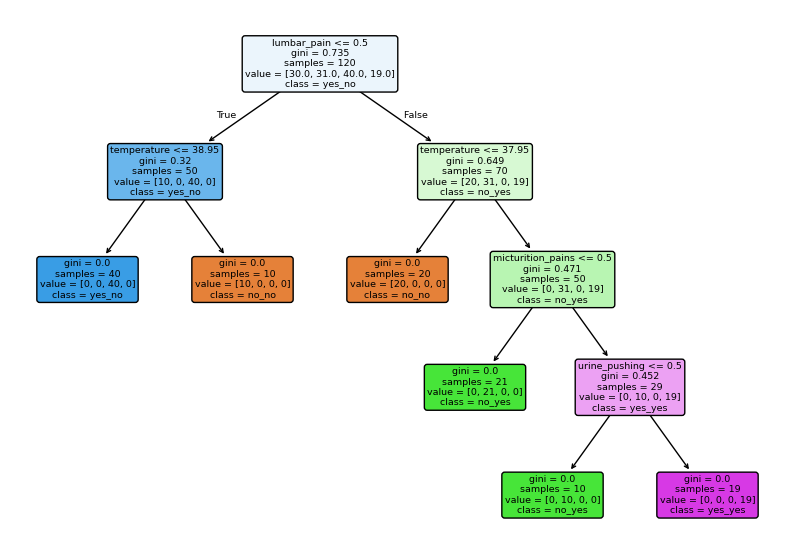

CV accuracy for chosen alpha: 0.9583333333333334
Leaves: 4


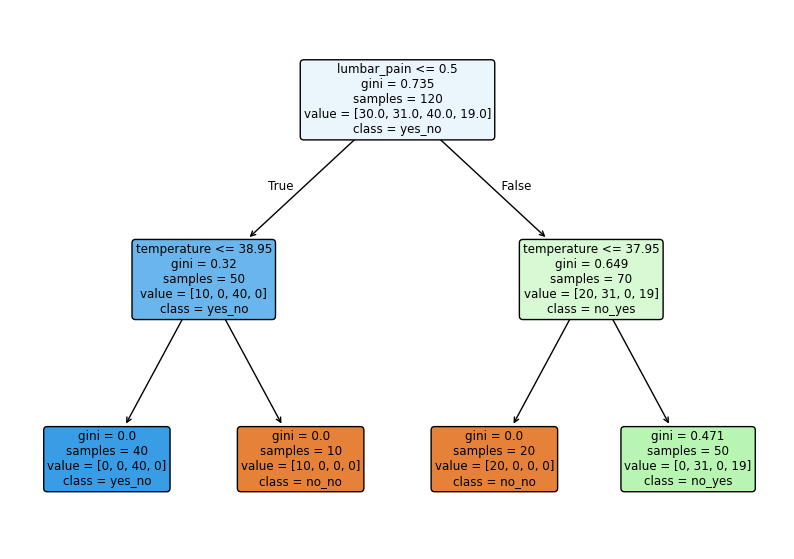

In [22]:
path = tree.cost_complexity_pruning_path(X, y)
alphas = path.ccp_alphas

mean_scores = []
score_stds = []

for alpha in alphas:
    model = DecisionTreeClassifier(ccp_alpha = alpha, random_state = 1018)
    scores = cross_val_score(model, X, y, cv = 5)
    mean_scores.append(scores.mean())
    score_stds.append(scores.std())

best_index = max(range(len(alphas)), key = lambda i: mean_scores[i])
cutoff = mean_scores[best_index] - score_stds[best_index] / (5 ** 0.5)

chosen_alpha = max(alphas[i] for i in range(len(alphas)) if mean_scores[i] >= cutoff)

pruned_tree = DecisionTreeClassifier(ccp_alpha = chosen_alpha, random_state=1018)
pruned_tree.fit(X, y)

print("Chosen alpha:", chosen_alpha)
print("Leaves before pruning:", tree.get_n_leaves())
print("Leaves after pruning:", pruned_tree.get_n_leaves())
print("Cross-validation accuracy:", mean_scores[best_index])


results = []

for alpha, score in zip(alphas, mean_scores):
    model = DecisionTreeClassifier(ccp_alpha = alpha, random_state = 1018)
    model.fit(X, y)
    results.append({"alpha": alpha, "leaves": model.get_n_leaves(), "cv_accuracy": score})

display(pd.DataFrame(results))

print(export_text(pruned_tree, feature_names=list(X.columns), decimals=2))

plt.figure(figsize = (10, 7))
plot_tree(pruned_tree, feature_names = X.columns, class_names = pruned_tree.classes_, filled = True, rounded = True)
plt.show()

chosen_index = list(alphas).index(chosen_alpha)
print("CV accuracy for chosen alpha:", mean_scores[chosen_index])

tree_4_leaf = DecisionTreeClassifier(ccp_alpha = alphas[1], random_state = 1018)
tree_4_leaf.fit(X, y)
print("Leaves:", tree_4_leaf.get_n_leaves())
plt.figure(figsize=(10, 7))
plot_tree(tree_4_leaf, feature_names = X.columns, class_names = tree_4_leaf.classes_, filled = True, rounded = True)
plt.show()

The 6-leaf tree has 95.8% cross-validation accuracy but pruning it to 4 leaves lowers accuracy to 77.5% and further pruning lowers it even more.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [23]:
data = pd.read_csv("communities.data", header = None, na_values = "?")

X = data.iloc[:, 5:-1]
y = data.iloc[:, -1]

X_train = X.iloc[:1495]
y_train = y.iloc[:1495]

X_test = X.iloc[1495:]
y_test = y.iloc[1495:]

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Predictor columns:", X.shape[1])

Training rows: 1495
Test rows: 499
Predictor columns: 122


### (b) Missing values

In [25]:
column_means = X_train.mean()

column_means = column_means.fillna(0)

X_train = X_train.fillna(column_means)
X_test = X_test.fillna(column_means)

### (c) Plot a correlation matrix

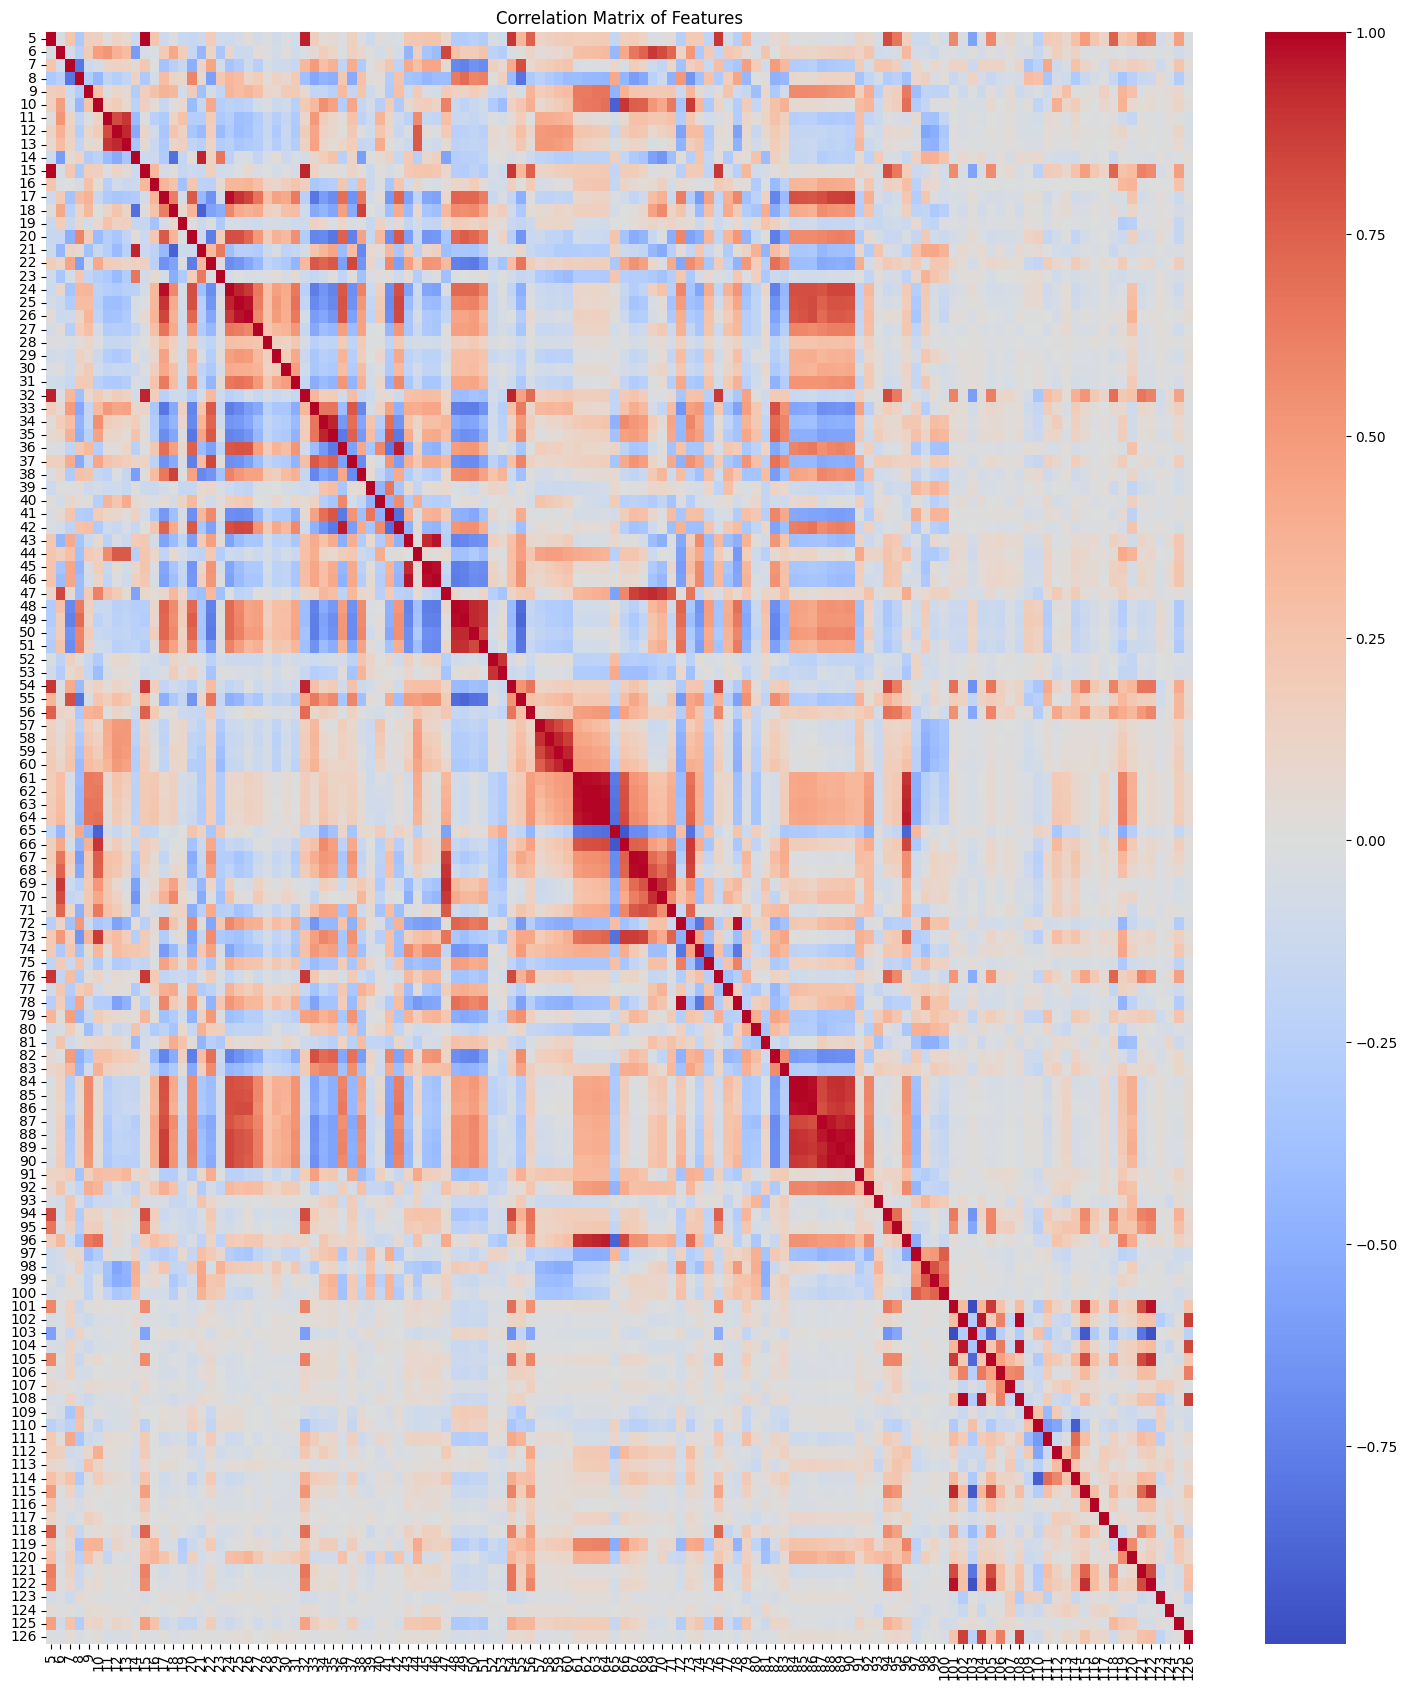

In [30]:
correlation_matrix = X_train.corr()

plt.figure(figsize = (15, 17))
sn.heatmap(correlation_matrix, cmap = "coolwarm", center = 0, xticklabels = True, yticklabels = True)

plt.xticks(rotation = 90)
plt.yticks()
plt.title("Correlation Matrix of Features")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [31]:
means = X_train.mean()
sample_sd = X_train.std(ddof = 1)

cv = sample_sd / means.replace(0, float("nan"))
cv_table = pd.DataFrame({"mean": means, "sample_sd": sample_sd, "CV": cv})

cv_table["CV (%)"] = cv * 100
cv_table

,mean,sample_sd,CV,CV (%)
5,0.058167,0.130359,2.241105,224.110462
6,0.461732,0.164284,0.355800,35.579957
7,0.179839,0.256970,1.428885,142.888542
8,0.752829,0.248594,0.330213,33.021266
9,0.153712,0.208910,1.359100,135.909968
...,...,...,...,...
122,0.080502,0.059852,0.743487,74.348659
123,0.713054,0.082528,0.115739,11.573888
124,0.451883,0.164029,0.362989,36.298927
125,0.093304,0.238201,2.552946,255.294551


### (e) Scatter plots and box plots for highest CV features

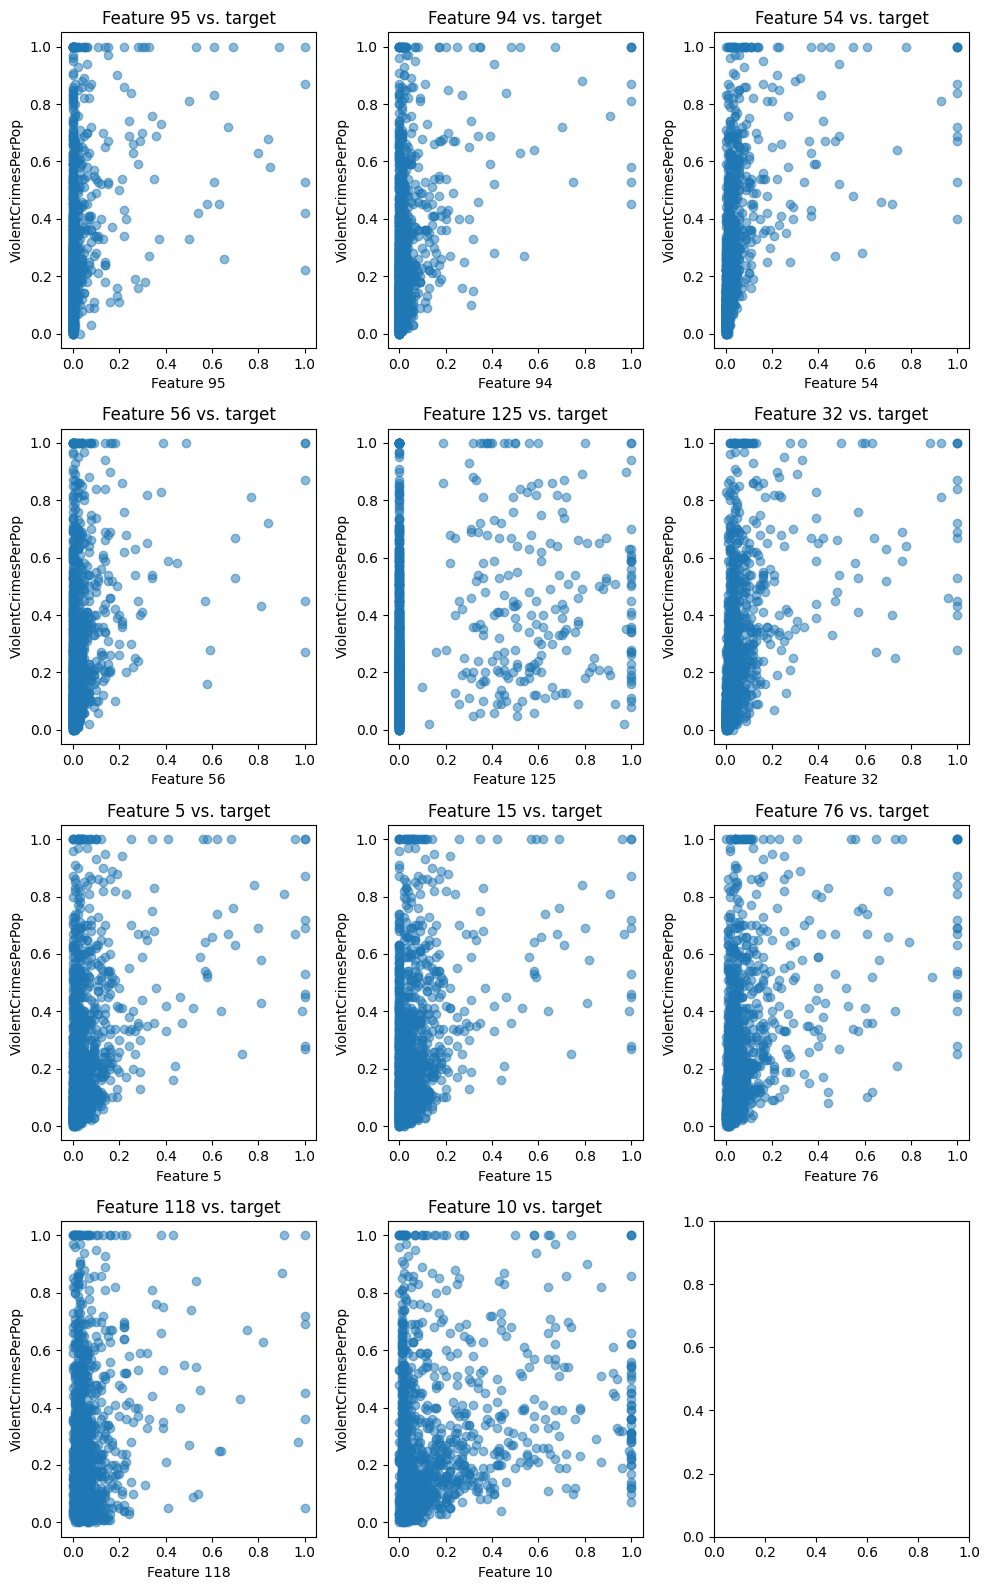

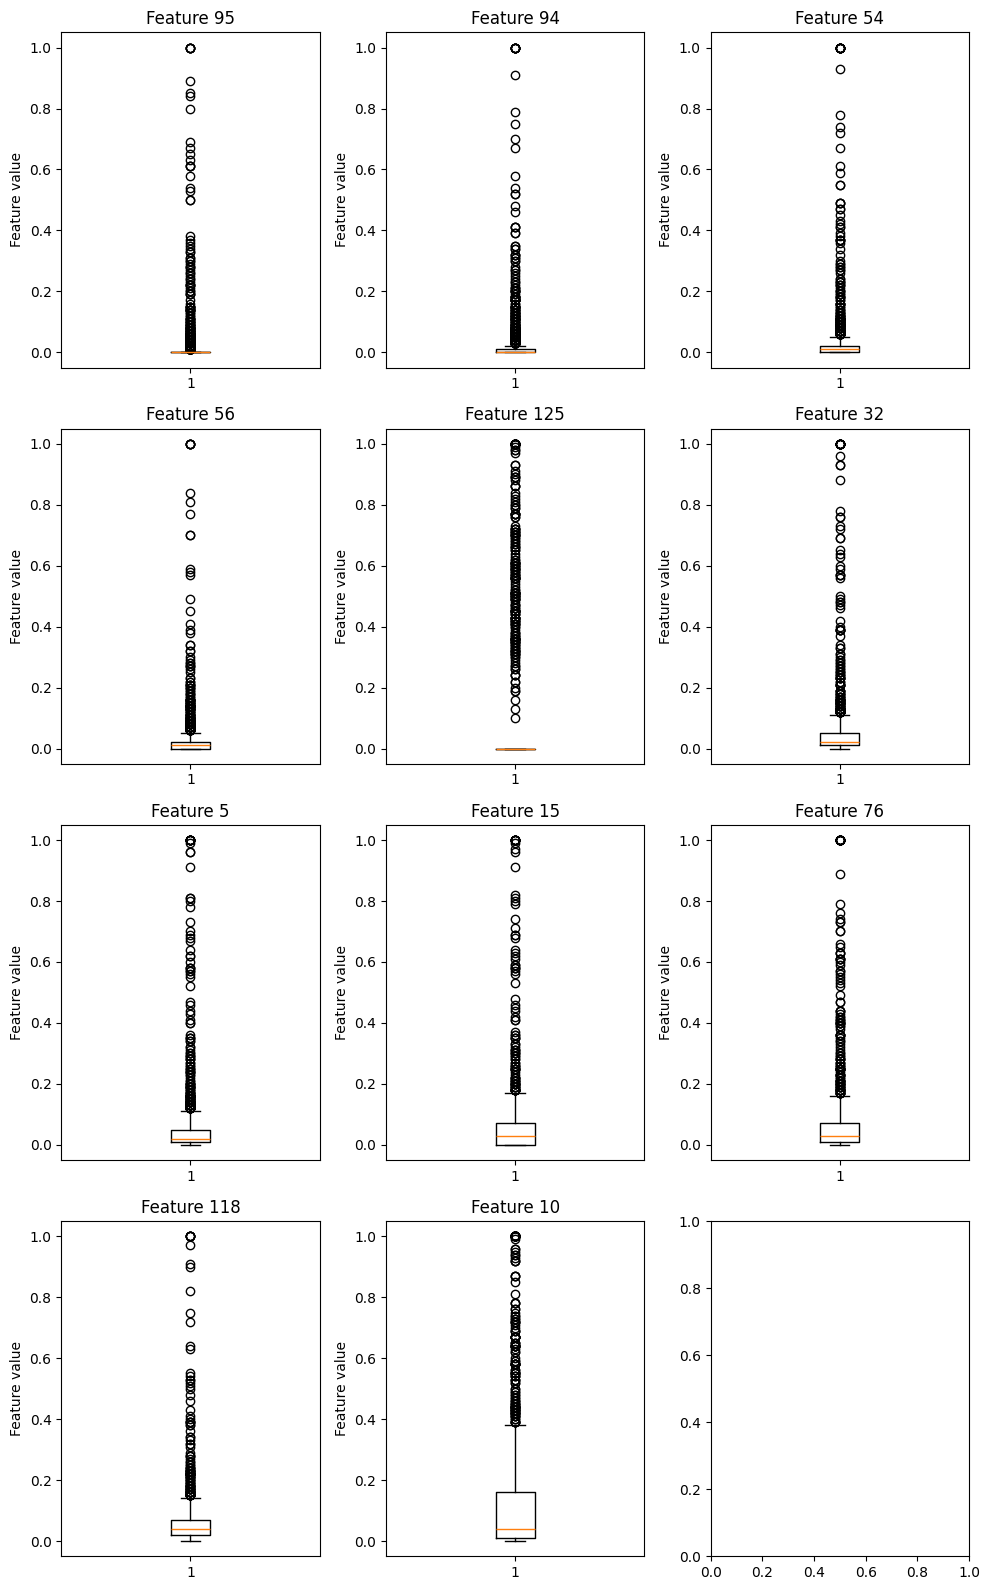

In [37]:
top_features = cv.sort_values(ascending = False).head(11).index

fig, axes = plt.subplots(4, 3, figsize=(10, 16))
for ax, feature in zip(axes.flat, top_features):
    ax.scatter(X_train[feature], y_train, alpha = 0.5)
    ax.set_title(f"Feature {feature} vs. target")
    ax.set_xlabel(f"Feature {feature}")
    ax.set_ylabel("ViolentCrimesPerPop")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 3, figsize = (10, 16))
for ax, feature in zip(axes.flat, top_features):
    ax.boxplot(X_train[feature])
    ax.set_title(f"Feature {feature}")
    ax.set_ylabel("Feature value")
plt.tight_layout()
plt.show()

### (f) Fit a linear model

In [41]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

test_error = mean_squared_error(y_test, y_pred)
print("Test MSE:", test_error)

Test MSE: 0.01814197113553009


### (g) Fit a ridge regression model

In [43]:
ridge_pipeline = make_pipeline(StandardScaler(), Ridge())

parameters = {"ridge__alpha": np.logspace(-3, 3, 100)}

ridge_cv = GridSearchCV(ridge_pipeline, parameters, cv = 5, scoring = "neg_mean_squared_error")
ridge_cv.fit(X_train, y_train)

y_pred = ridge_cv.predict(X_test)

print("Best lambda:", ridge_cv.best_params_["ridge__alpha"])
print("Test MSE:", mean_squared_error(y_test, y_pred))

Best lambda: 81.11308307896873
Test MSE: 0.01753768480288761


### (h) Fit a LASSO model

In [45]:
lasso_raw = LassoCV(cv = 5, max_iter = 100000)
lasso_raw.fit(X_train, y_train)

raw_predictions = lasso_raw.predict(X_test)

print("Raw features")
print("Chosen lambda:", lasso_raw.alpha_)
print("Test MSE:", mean_squared_error(y_test, raw_predictions))
print("Selected feature columns:", list(X_train.columns[lasso_raw.coef_ != 0]))

scaler = StandardScaler()
X_train_standardized = scaler.fit_transform(X_train)
X_test_standardized = scaler.transform(X_test)

lasso_standardized = LassoCV(cv = 5, max_iter = 100000)
lasso_standardized.fit(X_train_standardized, y_train)

standardized_predictions = lasso_standardized.predict(X_test_standardized)

print("Standardized features")
print("Chosen lambda:", lasso_standardized.alpha_)
print("Test MSE:", mean_squared_error(y_test, standardized_predictions))
print("Selected feature columns:", list(X_train.columns[lasso_standardized.coef_ != 0]))

Raw features
Chosen lambda: 0.00011614723626829846
Test MSE: 0.017758209216319674
Selected feature columns: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 97, 99, 104, 105, 107, 109, 111, 113, 115, 116, 117, 118, 119, 120, 123, 124, 125, 126]
Standardized features
Chosen lambda: 0.0007630833878262516
Test MSE: 0.017805339276862273
Selected feature columns: [7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 58, 60, 64, 66, 68, 69, 72, 73, 74, 76, 77, 79, 80, 81, 82, 83, 87, 90, 91, 92, 93, 94, 95, 96, 99, 104, 105, 107, 109, 110, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 123, 124]


The raw and standardized LASSO models had almost the same test error, with the raw model doing slightly better (0.01776 vs. 0.01781). They also selected mostly the same features, so standardizing changed a few selections but didn't really improve the model's performance

### (i) Fit a PCR model

In [47]:
pcr_pipeline = make_pipeline(StandardScaler(),PCA(), LinearRegression())
parameters = {"pca__n_components": range(1, X_train.shape[1] + 1)}

pcr_cv = GridSearchCV(pcr_pipeline, parameters, cv = 5, scoring="neg_mean_squared_error")

pcr_cv.fit(X_train, y_train)
y_pred = pcr_cv.predict(X_test)

print("Best number of components:", pcr_cv.best_params_["pca__n_components"])
print("Test MSE:", mean_squared_error(y_test, y_pred))

Best number of components: 95
Test MSE: 0.01839293123038777


### (j) Fit a boosting tree

In [49]:
xgb_model = XGBRegressor(objective="reg:squarederror", random_state = 1018, n_jobs = -1)

parameters = {"reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]}

xgb_cv = GridSearchCV(xgb_model, parameters, cv = 5, scoring = "neg_mean_squared_error")
xgb_cv.fit(X_train, y_train)
y_pred = xgb_cv.predict(X_test)

print("Best alpha:", xgb_cv.best_params_["reg_alpha"])
print("Test MSE:", mean_squared_error(y_test, y_pred))

Best alpha: 1
Test MSE: 0.017747461401957192
